In [4]:
import json
from pathlib import Path
import re
import pandas as pd


def clean_player_name(name: str) -> str:
  if not name or not isinstance(name, str):
    return ''
  clean = re.sub(r'\s*-\s*-', '', name).strip()
  return clean


def load_all_games(
    processed_dir: str = 'data/processed',
) -> tuple[pd.DataFrame, pd.DataFrame]:
  path = Path(processed_dir)
  games_list = []
  player_stats_list = []

  for json_file in path.glob('match_*.json'):
    with open(json_file, 'r', encoding='utf-8') as f:
      data = json.load(f)

    meta = data.get('metadata', {})
    match_id = json_file.stem.replace('match_', '')

    games_list.append({
        'match_id': match_id,
        'game_number': meta.get('game_number', ''),
        'date': meta.get('date', ''),
        'home_team': meta.get('home_team', ''),
        'away_team': meta.get('away_team', ''),
        'final_score': meta.get('final_score', ''),
        'spectators': meta.get('spectators', 0),
    })

    # Beide Kader (Heim und Gast) vollständig verarbeiten
    for team_type, kader_key in [
        ('Heim', 'home_kader'),
        ('Gast', 'away_kader'),
    ]:
      kader = data.get(kader_key, [])
      team_name = meta.get(
          'home_team' if team_type == 'Heim' else 'away_team', ''
      )

      for p in kader:
        raw_name = p.get('Name', '')
        name = clean_player_name(raw_name)

        nr = str(p.get('Nr', '')).strip()
        if not name or nr in ['A', 'B', 'C', 'D', 'H']:
          continue

        # Tore auslesen
        tore_str = str(p.get('Tore', '')).strip()
        tore = int(tore_str) if tore_str.isdigit() else 0

        # 7m Tore auslesen
        seven_m_str = str(p.get('7m_Tore', '')).strip()
        seven_m_goals = 0
        if '/' in seven_m_str:
          try:
            seven_m_goals = int(seven_m_str.split('/')[0])
          except ValueError:
            seven_m_goals = 0

        player_stats_list.append({
            'match_id': match_id,
            'team': team_name,
            'nr': nr,
            'person': name,
            'tore': tore,
            '7m_tore': seven_m_goals,
        })

  games_df = pd.DataFrame(games_list)
  player_stats_df = pd.DataFrame(player_stats_list)

  return games_df, player_stats_df

,home_team,Heimspiele,Zuschauer_Gesamt,Zuschauer_Schnitt
1,FRANKFURTER HC,3,1103,367.7
9,TUS 97 BIELEFELD/JÖLLENBECK,3,963,321.0
4,HSG EIDER HARDE,3,852,284.0
6,SV FORTUNA 50 NEUBRANDENBURG,2,480,240.0
5,SC SFN VECHTA,3,660,220.0
7,SV GRÜN WEISS SCHWERIN,1,199,199.0
10,TV HANNOVER-BADENSTEDT,3,467,155.7
0,BUXTEHUDER SV II,3,421,140.3
8,TSV NORD HARRISLEE,2,256,128.0
3,HSG BLOMBERG-LIPPE 2,4,454,113.5


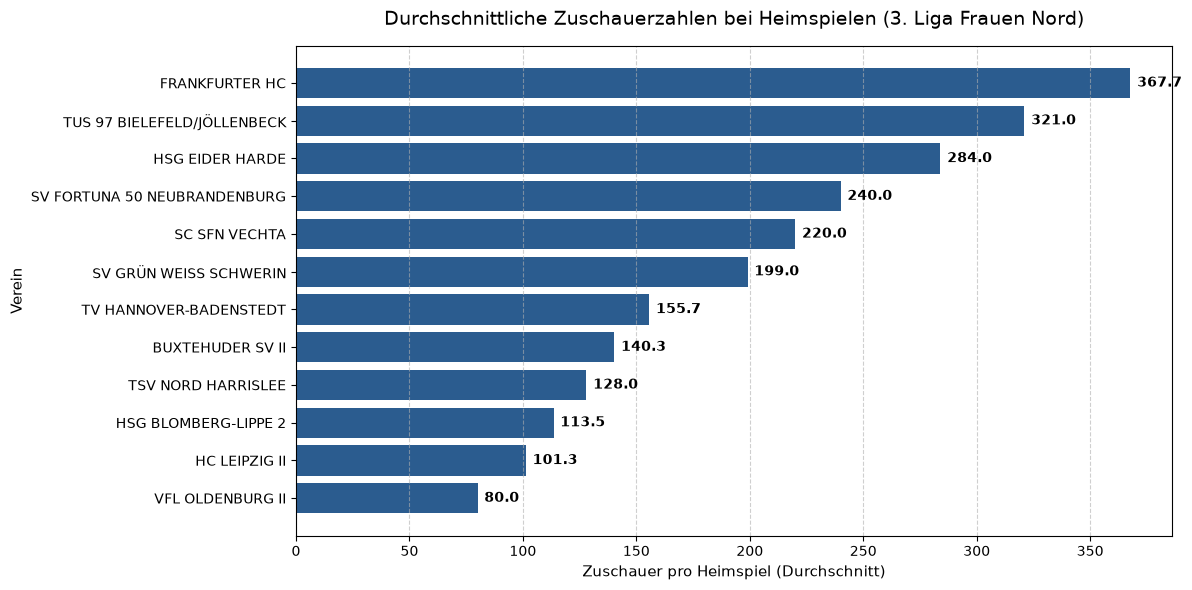

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from src.analytics import load_all_games

# 1. Daten aus allen aufbereiteten Spielen laden
games_df, _ = load_all_games()

# 2. Spiele mit gültigen Zuschauerangaben (> 0) filtern
valid_games = games_df[games_df["spectators"] > 0].copy()

# 3. Durchschnitt, Gesamtzahl und Anzahl der Heimspiele pro Verein berechnen
spectator_stats = valid_games.groupby("home_team").agg(
    Heimspiele=("spectators", "count"),
    Zuschauer_Gesamt=("spectators", "sum"),
    Zuschauer_Schnitt=("spectators", "mean")
).reset_index()

# Nach dem höchsten Zuschauerschnitt sortieren und runden
spectator_stats = spectator_stats.sort_values(by="Zuschauer_Schnitt", ascending=False)
spectator_stats["Zuschauer_Schnitt"] = spectator_stats["Zuschauer_Schnitt"].round(1)

# 4. Tabelle im Notebook anzeigen
display(spectator_stats)

# 5. Balkendiagramm direkt unter der Zelle ausgeben
plt.figure(figsize=(12, 6))
bars = plt.barh(spectator_stats["home_team"], spectator_stats["Zuschauer_Schnitt"], color="#2b5c8f")

# Werte direkt an den Balken beschriften
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Durchschnittliche Zuschauerzahlen bei Heimspielen (3. Liga Frauen Nord)", fontsize=14, pad=15)
plt.xlabel("Zuschauer pro Heimspiel (Durchschnitt)", fontsize=11)
plt.ylabel("Verein", fontsize=11)
plt.gca().invert_yaxis()  # Höchster Wert ganz oben
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()

# Grafik im Notebook anzeigen
plt.show()




Ausgewertet: 31 Spiele | Übersprungen: 101
  - 392527: keine Timeline
  - 392529: keine Timeline
  - 392530: keine Timeline
  - 392538: HSG BLOMBERG-LIPPE 2 - TV HANNOVER-BADENSTEDT: Lücke bei 06:39: Stand 3:2, gezählt 1:0
  - 392546: HSG BLOMBERG-LIPPE 2 - VFL OLDENBURG II: Lücke bei 02:11: Stand 2:0, gezählt 1:0
  - 392549: keine Timeline
  - 392550: keine Timeline
  - 392551: keine Timeline
  - 392552: keine Timeline
  - 392553: keine Timeline
  - 392554: keine Timeline
  - 392555: keine Timeline
  - 392556: keine Timeline
  - 392557: keine Timeline
  - 392558: keine Timeline
  … und 86 weitere

=== GESAMTBILANZ: PERFORMANCE IN ÜBER-/UNTERZAHL ===


Phasen (Häufigkeit)  \
Situation               Team                                                
Doppelte Überzahl (+2)  SV FORTUNA 50 NEUBRANDENBURG                    1   
                        SV GRÜN WEISS SCHWERIN                          1   
                        TSV NORD HARRISLEE                              1   
                        TUS 97 BIELEFELD/JÖLLENBECK                     1   
                        HSG BLOMBERG-LIPPE 2                            1   
                        HSG EIDER HARDE                                 1   
                        SC SFN VECHTA                                   1   
                        VFL OLDENBURG II                                1   
Einfache Überzahl (+1)  TV HANNOVER-BADENSTEDT                         14   
                        FRANKFURTER HC                                 12   
                        VFL OLDENBURG II                               24   
                        SV FORTUNA 50 NEUBRANDENBURG                   20   
                        TUS 97 BIELEFELD/JÖLLENBECK                    18   
                        HSG EIDER HARDE                                23   
                        HC LEIPZIG II                                  14   
                        SV GRÜN WEISS SCHWERIN                         14   
                        SC SFN VECHTA                                  19   
                        TSV NORD HARRISLEE                             15   
                        HSG BLOMBERG-LIPPE 2                           14   
                        BUXTEHUDER SV II                                9   
Einfache Unterzahl (-1) SV GRÜN WEISS SCHWERIN                         15   
                        TUS 97 BIELEFELD/JÖLLENBECK                    11   
                        TV HANNOVER-BADENSTEDT                         15   
                        SC SFN VECHTA                                  12   
                        VFL OLDENBURG II                               18   
                        FRANKFURTER HC                                 16   
                        TSV NORD HARRISLEE                             19   
                        BUXTEHUDER SV II                               14   
                        HSG BLOMBERG-LIPPE 2                           12   
                        SV FORTUNA 50 NEUBRANDENBURG                   22   
                        HC LEIPZIG II                                  22   
                        HSG EIDER HARDE                                20   
Doppelte Unterzahl (-2) SC SFN VECHTA                                   1   
                        TV HANNOVER-BADENSTEDT                          2   
                        SV FORTUNA 50 NEUBRANDENBURG                    1   
                        VFL OLDENBURG II                                1   
                        HC LEIPZIG II                                   3   

                                                      Eigene Tore  Gegentore  \
Situation               Team                                                   
Doppelte Überzahl (+2)  SV FORTUNA 50 NEUBRANDENBURG            1          0   
                        SV GRÜN WEISS SCHWERIN                  1          0   
                        TSV NORD HARRISLEE                      1          0   
                        TUS 97 BIELEFELD/JÖLLENBECK             1          0   
                        HSG BLOMBERG-LIPPE 2                    1          1   
                        HSG EIDER HARDE                         0          0   
                        SC SFN VECHTA                           0          0   
                        VFL OLDENBURG II                        0          0   
Einfache Überzahl (+1)  TV HANNOVER-BADENSTEDT                 23          5   
                        FRANKFURTER HC                         17          2   
                        VFL OLDENBURG II                       27         12   
          

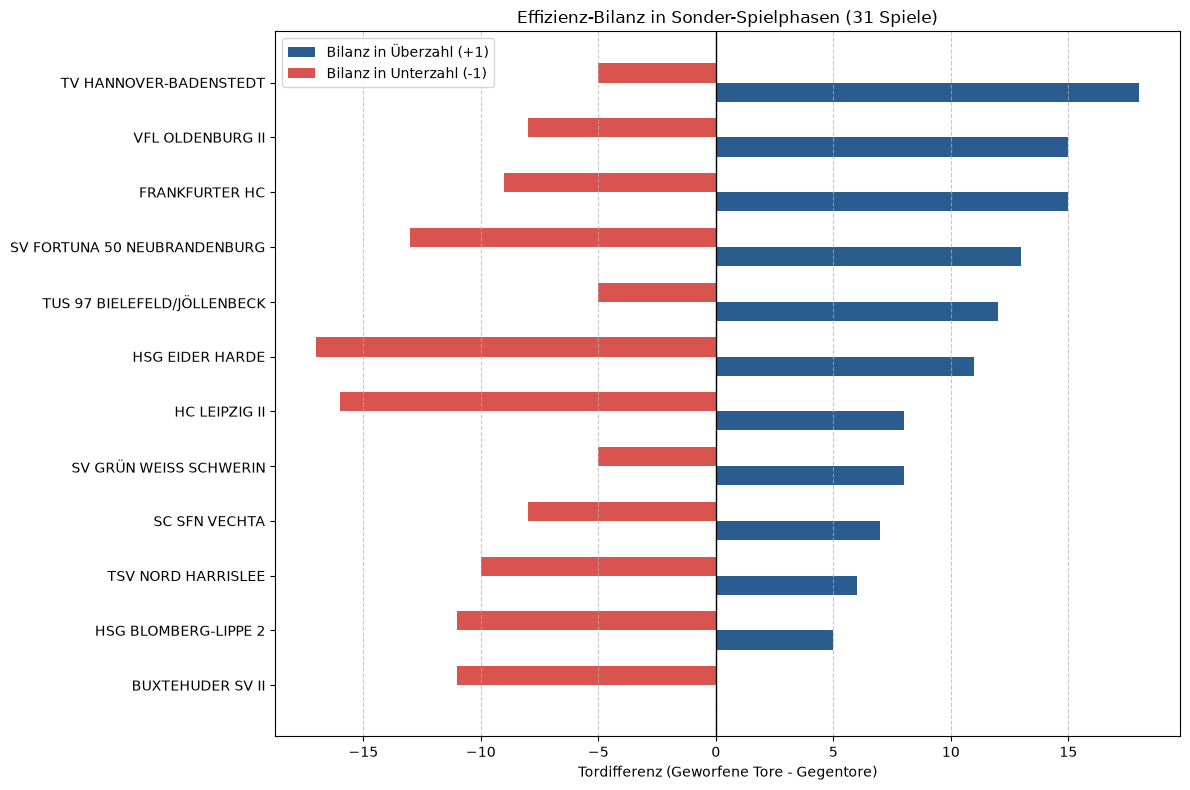

In [45]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:  # in Jupyter hübsche Tabellen, sonst normales print
    from IPython.display import display
except ImportError:
    display = print

# ----------------------------------------------------------------------------
# Einstellungen
# ----------------------------------------------------------------------------
DATA_DIR = Path("data/processed")
PENALTY_SECONDS = 120          # Dauer einer Zeitstrafe
MATCH_SECONDS = 60 * 60
ONLY_COMPLETE_MATCHES = True   # Spiele mit lückenhaftem Spielverlauf überspringen
EXCLUDE_7M = False             # True = Siebenmeter-Tore nicht mitzählen

GOAL_EVENTS = {"tor", "siebenmeter tor"}
# Disqualifikation = Team spielt ebenfalls 2 Minuten in Unterzahl
PENALTY_KEYS = ("zwei minuten", "disqualifikation")
SIDE_MAP = {"heim": "home", "gast": "away"}

SIT_LABELS = {
    2: "Doppelte Überzahl (+2)",
    1: "Einfache Überzahl (+1)",
    -1: "Einfache Unterzahl (-1)",
    -2: "Doppelte Unterzahl (-2)",
}


# ----------------------------------------------------------------------------
# Hilfsfunktionen
# ----------------------------------------------------------------------------
def to_seconds(t):
    try:
        m, s = str(t).split(":")
        return int(m) * 60 + int(s)
    except ValueError:
        return None


def fmt(sec):
    return f"{sec // 60:02d}:{sec % 60:02d}"


def load_events(timeline):
    """Timeline-Einträge -> bereinigte, nach Zeit sortierte Events."""
    events = []
    for idx, ev in enumerate(timeline):
        sec = to_seconds(ev.get("time", ""))
        if sec is None:
            continue
        events.append({
            "idx": idx,
            "sec": sec,
            "side": SIDE_MAP.get(str(ev.get("team", "")).strip().lower()),
            "event": str(ev.get("event", "")).strip().lower(),
            "score": str(ev.get("score", "")).strip(),
        })
    # stabil: bei gleicher Sekunde bleibt die Original-Reihenfolge erhalten
    events.sort(key=lambda e: (e["sec"], e["idx"]))
    return events


def find_problems(events, meta):
    """Prüft, ob der Spielverlauf lückenlos ist (Torfolge == Spielstand)."""
    problems = []
    h = a = 0
    for e in events:
        if e["event"] in GOAL_EVENTS and e["side"]:
            if e["side"] == "home":
                h += 1
            else:
                a += 1
            if e["score"]:
                try:
                    sh, sa = map(int, e["score"].split(":"))
                except ValueError:
                    continue
                if (sh, sa) != (h, a):
                    problems.append(
                        f"Lücke bei {fmt(e['sec'])}: Stand {sh}:{sa}, gezählt {h}:{a}"
                    )
                    h, a = sh, sa  # neu synchronisieren

    final = meta.get("final_score")
    if not final:
        problems.append("kein Endstand in den Metadaten")
    elif final != f"{h}:{a}":
        problems.append(f"Endstand {final}, aus Timeline {h}:{a}")
    return problems


def get_penalties(events):
    pens, seen = [], set()
    for e in events:
        if e["side"] and any(k in e["event"] for k in PENALTY_KEYS):
            key = (e["side"], e["sec"])
            if key in seen:  # z. B. "Zwei Minuten" + "Disqualifikation" gleichzeitig
                continue
            seen.add(key)
            pens.append({"side": e["side"], "start": e["sec"], "key": (e["sec"], e["idx"])})
    return pens


def home_net(pens, sec, order_key=None):
    """Netto-Überzahl des Heimteams (+2 … -2) zum Zeitpunkt sec.

    order_key=(sec, idx) sorgt dafür, dass nur Strafen zählen, die in der
    Timeline VOR dem betrachteten Tor stehen (relevant bei gleicher Sekunde).
    """
    h = a = 0
    for p in pens:
        if sec >= p["start"] + PENALTY_SECONDS:
            continue
        if order_key is None:
            if p["start"] > sec:
                continue
        elif p["key"] >= order_key:
            continue
        if p["side"] == "home":
            h += 1
        else:
            a += 1
    return min(a, 2) - min(h, 2)


def analyze_match(events, home, away):
    """Liefert Zeilen (Team, Stufe, Phasen, Sekunden, Tore, Gegentore) eines Spiels."""
    pens = get_penalties(events)
    end = max(MATCH_SECONDS, max((e["sec"] for e in events), default=0))
    teams = {"home": home, "away": away}
    acc = defaultdict(lambda: {"Phasen": 0, "Sekunden": 0, "Tore": 0, "Gegentore": 0})

    # --- Dauer & Anzahl der Phasen -------------------------------------------
    points = {0, end}
    for p in pens:
        points |= {min(p["start"], end), min(p["start"] + PENALTY_SECONDS, end)}
    points = sorted(points)

    prev = 0
    for t0, t1 in zip(points, points[1:]):
        net = home_net(pens, t0)
        if net:
            acc[("home", net)]["Sekunden"] += t1 - t0
            acc[("away", -net)]["Sekunden"] += t1 - t0
            if net != prev:  # neue Phase beginnt
                acc[("home", net)]["Phasen"] += 1
                acc[("away", -net)]["Phasen"] += 1
        prev = net

    # --- Tore -----------------------------------------------------------------
    for e in events:
        if e["event"] not in GOAL_EVENTS or not e["side"]:
            continue
        if EXCLUDE_7M and "siebenmeter" in e["event"]:
            continue
        net_home = home_net(pens, e["sec"], (e["sec"], e["idx"]))
        if not net_home:
            continue
        scorer = e["side"]
        other = "away" if scorer == "home" else "home"
        net_scorer = net_home if scorer == "home" else -net_home
        acc[(scorer, net_scorer)]["Tore"] += 1
        acc[(other, -net_scorer)]["Gegentore"] += 1

    return [
        {"Team": teams[side], "Stufe": lab, **vals}
        for (side, lab), vals in acc.items()
    ]


# ----------------------------------------------------------------------------
# Alle Spiele laden und auswerten
# ----------------------------------------------------------------------------
rows, skipped, n_ok = [], [], 0

for json_file in sorted(DATA_DIR.glob("match_*.json")):
    match_id = json_file.stem.replace("match_", "")
    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    meta = data.get("metadata", {})
    home, away = meta.get("home_team", ""), meta.get("away_team", "")
    if not home or not away:
        skipped.append((match_id, "Teams fehlen"))
        continue

    events = load_events(data.get("timeline", []))
    if not events:
        skipped.append((match_id, "keine Timeline"))
        continue

    problems = find_problems(events, meta)
    if problems and ONLY_COMPLETE_MATCHES:
        skipped.append((match_id, f"{home} - {away}: {problems[0]}"))
        continue

    for r in analyze_match(events, home, away):
        r["match_id"] = match_id
        rows.append(r)
    n_ok += 1

print(f"Ausgewertet: {n_ok} Spiele | Übersprungen: {len(skipped)}")
for mid, reason in skipped[:15]:
    print(f"  - {mid}: {reason}")
if len(skipped) > 15:
    print(f"  … und {len(skipped) - 15} weitere")

if not rows:
    raise SystemExit("Keine auswertbaren Spiele gefunden.")

# ----------------------------------------------------------------------------
# Gesamttabelle
# ----------------------------------------------------------------------------
raw_df = pd.DataFrame(rows)
situations_df = (
    raw_df.groupby(["Team", "Stufe"], as_index=False)[["Phasen", "Sekunden", "Tore", "Gegentore"]].sum()
)
situations_df["Minuten"] = (situations_df["Sekunden"] / 60).round(1)
situations_df["Bilanz (Diff)"] = situations_df["Tore"] - situations_df["Gegentore"]
mins = situations_df["Sekunden"].replace(0, np.nan) / 60
situations_df["Tore pro 2 Min"] = (situations_df["Tore"] / mins * 2).round(2)
situations_df["Gegentore pro 2 Min"] = (situations_df["Gegentore"] / mins * 2).round(2)
situations_df["Situation"] = situations_df["Stufe"].map(SIT_LABELS)

table = (
    situations_df.drop(columns=["Sekunden"])
    .rename(columns={"Phasen": "Phasen (Häufigkeit)", "Tore": "Eigene Tore"})
    .sort_values(by=["Stufe", "Bilanz (Diff)"], ascending=[False, False])
    .set_index(["Situation", "Team"])
    .drop(columns=["Stufe"])
)

print("\n=== GESAMTBILANZ: PERFORMANCE IN ÜBER-/UNTERZAHL ===")
display(table)

# ----------------------------------------------------------------------------
# Visualisierung (einfache Über-/Unterzahl)
# ----------------------------------------------------------------------------
pivot = (
    situations_df[situations_df["Stufe"].isin([1, -1])]
    .pivot_table(index="Team", columns="Stufe", values="Bilanz (Diff)", aggfunc="sum")
    .reindex(columns=[1, -1])
    .fillna(0)
    .sort_values(by=1)
)

y_pos = np.arange(len(pivot))
width = 0.35

fig, ax = plt.subplots(figsize=(12, max(6, 0.5 * len(pivot) + 2)))
ax.barh(y_pos - width / 2, pivot[1], width, label="Bilanz in Überzahl (+1)", color="#2b5c8f")
ax.barh(y_pos + width / 2, pivot[-1], width, label="Bilanz in Unterzahl (-1)", color="#d9534f")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Tordifferenz (Geworfene Tore - Gegentore)")
ax.set_title(f"Effizienz-Bilanz in Sonder-Spielphasen ({n_ok} Spiele)")
ax.set_yticks(y_pos)
ax.set_yticklabels(pivot.index)
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [44]:
import json
from pathlib import Path
import pandas as pd

# Pfad zu den verarbeiteten JSON-Dateien
processed_dir = Path("data/processed")

# Liste zum Sammeln aller Spieler-Statistiken
all_players = []

# Alle match_*.json Dateien durchgehen
for json_path in processed_dir.glob("match_*.json"):
    try:
        with open(json_path, "r", encoding="utf-8") as f:
            match_data = json.load(f)
            
        match_id = match_data.get("metadata", {}).get("match_id")
        
        # Beide Teams (home und away) durchgehen
        for side_key in ["home", "away"]:
            team_info = match_data.get("teams", {}).get(side_key, {})
            team_name = team_info.get("name", "Unbekanntes Team")
            
            # Alle Spielerinnen/Spieler des Teams durchgehen
            for player in team_info.get("players", []):
                name = player.get("name")
                goals = player.get("goals", 0)
                
                if name:
                    all_players.append({
                        "Spieler/in": name,
                        "Team": team_name,
                        "Tore": goals,
                        "Match-ID": match_id
                    })
    except Exception as e:
        print(f"Fehler beim Lesen von {json_path.name}: {e}")

# In einen Pandas DataFrame umwandeln
df_players = pd.DataFrame(all_players)

if not df_players.empty:
    # Nach Spieler/in und Team gruppieren und Tore über alle Spiele summieren
    df_top_scorers = df_players.groupby(["Spieler/in", "Team"]).agg(
        Gesamt_Tore=("Tore", "sum"),
        Spiele_Anzahl=("Match-ID", "count")
    ).reset_index()
    
    # Nach den meisten Toren sortieren
    df_sorted = df_top_scorers.sort_values(by="Gesamt_Tore", ascending=False).reset_index(drop=True)
    
    print("Die besten Torschützen:")
    display(df_sorted.head(20)) # Zeigt die Top 20
else:
    print("Keine Spielerdaten gefunden.")

Die besten Torschützen:


,Spieler/in,Team,Gesamt_Tore,Spiele_Anzahl
0,Ellis Meg Bruhn,HSG EIDER HARDE,56,6
1,Svenja Ruhöfer,SC SFN VECHTA,53,6
2,Joana Rafaela Pires,FRANKFURTER HC,44,6
3,Amelie Petra Gabriel,BUXTEHUDER SV II,41,5
4,Liah Wiederhöft,TSV NORD HARRISLEE,37,9
5,Fine Stenzel,SV FORTUNA 50 NEUBRANDENBURG,37,5
6,Maja Schönefeld,BUXTEHUDER SV II,35,4
7,Madlen Kloska,SV FORTUNA 50 NEUBRANDENBURG,33,5
8,Josefine Jakobsen,SV GRÜN WEISS SCHWERIN,32,5
9,Charlotte Beier,HSG BLOMBERG-LIPPE 2,31,6


In [43]:
import json
from pathlib import Path
import pandas as pd

# Pfad zu den generierten JSON-Dateien
processed_dir = Path("data/processed")

# Dictionary zum Sammeln der 7m-Statistiken pro Spielerin und Team
player_stats = {}

# Alle match_*.json Dateien im Ordner durchgehen
for json_path in processed_dir.glob("match_*.json"):
    try:
        with open(json_path, "r", encoding="utf-8") as f:
            match_data = json.load(f)
            
        # Prüfen, ob die Datei von der Pipeline als fehlerfrei für den Kader markiert wurde
        parse_info = match_data.get("parse_info", {})
        if not parse_info.get("roster_ok"):
            continue
            
        # Beide Teams (home und away) durchgehen
        for side in ["home", "away"]:
            team_data = match_data.get("teams", {}).get(side, {})
            # Name standardisieren, um Duplikate zu vermeiden
            team_name = team_data.get("name", "Unbekannt").strip().title()
            
            # Alle Spielerinnen des Teams durchgehen
            for player in team_data.get("players", []):
                name = player.get("name", "").strip().title()
                seven_m = player.get("seven_m") # Erwartetes Format: "Tore/Geworfen" z.B. "7/8"
                
                if name and seven_m and "/" in seven_m:
                    try:
                        scored, total = map(int, seven_m.split("/"))
                        
                        key = (name, team_name)
                        if key not in player_stats:
                            player_stats[key] = {"Tore (7m)": 0, "Geworfen (7m)": 0, "Spiele": 0}
                        
                        player_stats[key]["Tore (7m)"] += scored
                        player_stats[key]["Geworfen (7m)"] += total
                        player_stats[key]["Spiele"] += 1
                        
                    except ValueError:
                        # Überspringen, falls das Format abweicht
                        continue
                        
    except Exception as e:
        print(f"Fehler beim Lesen von {json_path.name}: {e}")

# Daten filtern und in eine Liste für den DataFrame umwandeln
results = []
for (name, team), stats in player_stats.items():
    # Nur Spielerinnen mit mindestens 6 geworfenen 7m berücksichtigen
    if stats["Geworfen (7m)"] >= 6:
        quote = (stats["Tore (7m)"] / stats["Geworfen (7m)"]) * 100
        results.append({
            "Spielerin": name,
            "Team": team,
            "Tore (7m)": stats["Tore (7m)"],
            "Geworfen (7m)": stats["Geworfen (7m)"],
            "Quote (%)": round(quote, 1),
            "Spiele": stats["Spiele"]
        })

# Pandas DataFrame erstellen
df_7m = pd.DataFrame(results)

if not df_7m.empty:
    # Nach den meisten getroffenen 7m und dann nach der besten Quote sortieren
    df_sorted = df_7m.sort_values(by=["Tore (7m)", "Quote (%)"], ascending=[False, False]).reset_index(drop=True)
    
    print("Die besten 7m-Schützen (ab 6 geworfenen 7m):")
    # Schöne Tabellenausgabe in Jupyter
    display(df_sorted)
else:
    print("Keine Spielerinnen gefunden, die mindestens 6 Siebenmeter geworfen haben.")

Die besten 7m-Schützen (ab 6 geworfenen 7m):


,Spielerin,Team,Tore (7m),Geworfen (7m),Quote (%),Spiele
0,Ellis Meg Bruhn,Hsg Eider Harde,24,26,92.3,6
1,Svenja Ruhöfer,Sc Sfn Vechta,18,25,72.0,6
2,Olivia Schwarz,Sv Grün Weiss Schwerin,13,13,100.0,4
3,Franziska Rolf,Tus 97 Bielefeld/Jöllenbeck,13,16,81.2,3
4,Lydia Schürer,Hc Leipzig Ii,11,14,78.6,4
5,Charlotte Beier,Hsg Blomberg-Lippe 2,11,14,78.6,4
6,Amelie Petra Gabriel,Buxtehuder Sv Ii,11,15,73.3,5
7,Liah Wiederhöft,Tsv Nord Harrislee,10,13,76.9,5
8,Emma Reinemann,Vfl Oldenburg Ii,10,13,76.9,3
9,Lina Genz,Vfl Oldenburg Ii,8,8,100.0,3
